In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

B = "../data/lake/bronze"
books = pd.read_csv(f"{B}/books.csv")
customers = pd.read_csv(f"{B}/customers.csv")
orders = pd.read_csv(f"{B}/orders.csv")
reviews = pd.read_csv(f"{B}/reviews.csv")
print(len(books), len(customers), len(orders), len(reviews))


1000 515 3060 1200


In [2]:
def profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "null_pct": (df.isna().mean() * 100).round(1),
        "unique": df.nunique(),
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

profile(customers)


,dtype,non_null,null_pct,unique,example
customer_id,object,515,0.0,500,C0192
full_name,object,515,0.0,85,Amir bin Salleh
email,object,490,4.9,468,amir.salleh70@yahoo.com
phone,object,515,0.0,500,016-1230559
mykad,object,515,0.0,500,701103-01-9892
state,object,515,0.0,22,Johor
signup_date,object,515,0.0,390,2025-01-22


In [3]:
profile(books)


,dtype,non_null,null_pct,unique,example
book_id,object,1000,0.0,1000,its-only-the-himalayas_981
title,object,1000,0.0,999,It's Only the Himalayas
category,object,1000,0.0,50,Travel
price_raw,object,1000,0.0,903,£45.17
rating_raw,object,1000,0.0,5,Two
availability,object,1000,0.0,1,In stock
url,object,1000,0.0,1000,https://books.toscrape.com/catalogue/its-only-...
ingested_at,object,1000,0.0,1,2026-10-27T07:43:25.942438+00:00


In [4]:
profile(orders)


,dtype,non_null,null_pct,unique,example
order_id,object,3060,0.0,3000,O00001
customer_id,object,3060,0.0,531,C0141
book_id,object,3060,0.0,946,the-republic_78
quantity,int64,3060,0.0,5,2
order_date,object,3060,0.0,316,2026-03-02


In [5]:
profile(reviews)


,dtype,non_null,null_pct,unique,example
review_id,object,1200,0.0,1200,R00001
customer_id,object,1200,0.0,447,C0221
book_id,object,1200,0.0,696,the-art-book_490
stars,int64,1200,0.0,5,1
review_text,object,1161,3.2,234,Nicely wrapped with bubble wrap.
review_date,object,1200,0.0,240,2026-02-19


In [6]:
checks = {
    "customers: duplicate rows": customers.duplicated().sum(),
    "customers: missing email": customers["email"].isna().sum(),
    "orders: duplicate order_id": orders["order_id"].duplicated().sum(),
    "orders: quantity <= 0": (orders["quantity"] <= 0).sum(),
    "orders: date not YYYY-MM-DD": pd.to_datetime(
        orders["order_date"], format="%Y-%m-%d", errors="coerce").isna().sum(),
    "orders: unknown customer_id":
(~orders["customer_id"].isin(customers["customer_id"])).sum(),
    "orders: unknown book_id": (~orders["book_id"].isin(books["book_id"])).sum(),
    "reviews: empty text": reviews["review_text"].isna().sum(),
    "reviews: phone number in text": reviews["review_text"].str.contains(
        r"01\d-?\d{7}|\+601", na=False).sum(),
}
pd.Series(checks, name="issues").to_frame()


,issues
customers: duplicate rows,15
customers: missing email,25
orders: duplicate order_id,60
orders: quantity <= 0,32
orders: date not YYYY-MM-DD,91
orders: unknown customer_id,33
orders: unknown book_id,0
reviews: empty text,39
reviews: phone number in text,30


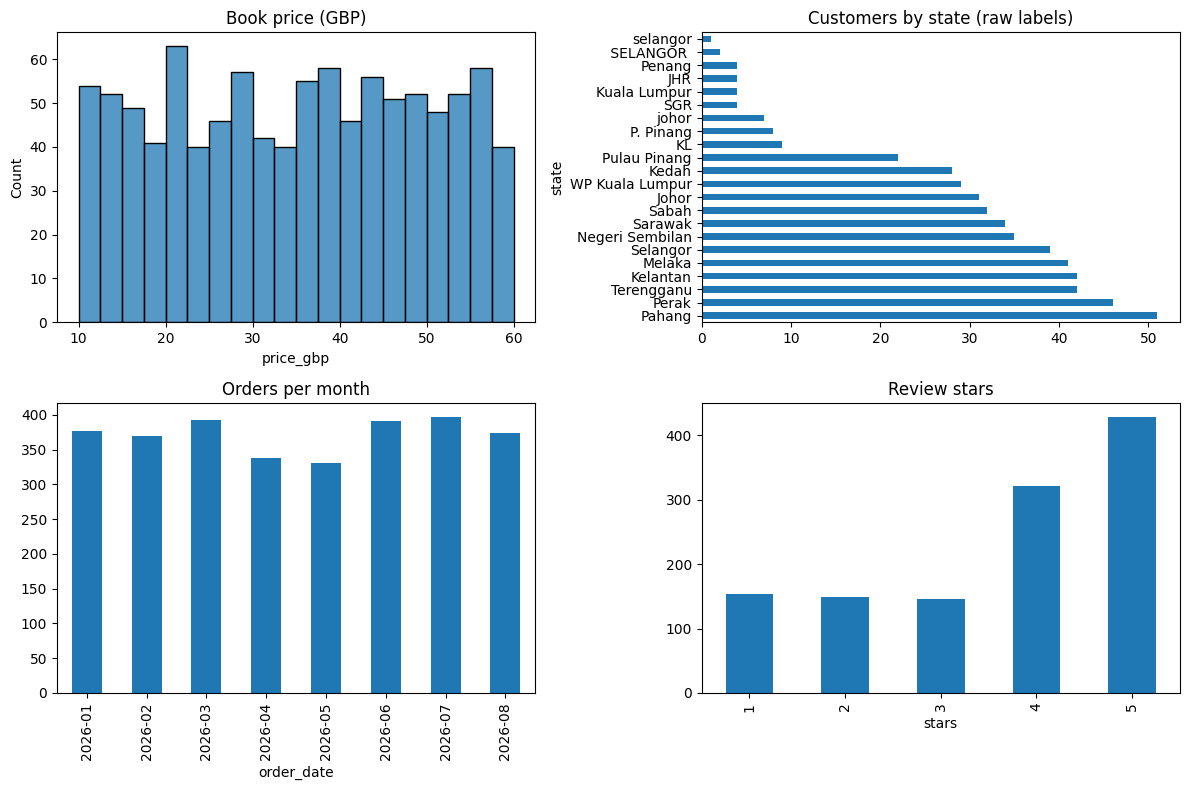

In [7]:
books["price_gbp"] = books["price_raw"].str.replace("£", "", regex=False).astype(float)
orders_ok = orders.assign(order_date=pd.to_datetime(
    orders["order_date"], format="%Y-%m-%d", errors="coerce"))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(books["price_gbp"], bins=20, ax=axes[0, 0]).set_title("Book price (GBP)")
customers["state"].value_counts().plot.barh(ax=axes[0, 1], title="Customers by state (raw labels)")
orders_ok.groupby(orders_ok["order_date"].dt.to_period("M")).size().plot.bar(
    ax=axes[1, 0], title="Orders per month")
reviews["stars"].value_counts().sort_index().plot.bar(ax=axes[1, 1], title="Review stars")
plt.tight_layout()


## Data Quality Report / 数据质量报告

| Dimension | Table.column | Check | Issues found | Fix planned for Lab 5 |
|---|---|---|---|---|
| Uniqueness | customers | duplicate rows (exact) | **15 rows** | drop exact duplicates |
| Uniqueness | orders.order_id | duplicate order_id | **60** | keep first, merge duplicates |
| Completeness | customers.email | missing values | **25** | keep row, flag email_missing |
| Completeness | reviews.review_text | empty text | **39** | keep row, flag review_missing |
| Validity | orders.quantity | quantity <= 0 | **32** | remove or correct <=0 orders |
| Validity | orders.order_date | mixed date formats (not YYYY-MM-DD) | **91** | parse all dates to YYYY-MM-DD |
| Consistency | customers.state | multiple labels per state (SGR/selangor/Selangor/SELANGOR; KL/Kuala Lumpur/WP Kuala Lumpur; JHR/Johor/johor) | **22 labels for 16 states** | map to standard state names |
| Integrity | orders.customer_id | unknown customer_id | **33** | remove orphan orders |
| Integrity | orders.book_id | unknown book_id | **0 (passed)** | — |
| Privacy | reviews.review_text | phone numbers leaked in free text | **30** | mask/remove phone numbers |

### 1. Personal data under PDPA 2010

The personal data columns are: `customers.full_name`, `customers.email`, `customers.phone`, `customers.mykad`, and `reviews.review_text` (which may contain personal data).

The most sensitive column is **`customers.mykad`** (MyKad national ID number), because it uniquely identifies a person and, unlike a phone number or email, it cannot be changed. Personal data also hides inside free text: our regex found **30 Malaysian phone numbers** typed directly into review_text, which must be masked before the data is shared.

### 2. Bias risk

If KedaiBuku uses review stars to decide which books to promote, the strong skew toward 4-star and 5-star reviews (about 750 combined, versus ~450 for 1–3 stars) means that books with few reviews or polarised opinions will be hidden. Customers who leave reviews are usually either very happy or very unhappy, so the average rating does not represent all buyers.

Looking at customers by state, the states with the fewest real customers are Pulau Pinang (~20), Kedah (~25), and WP Kuala Lumpur (~28); using these small samples for promotion decisions would be unreliable.
